# CsI(Tl)–SiPM：PID核心、尾部与波形关联

2026-10-30，承接[连续RC与联合噪声校准](codex_0001_csi_refined_rc.ipynb)。按用户要求先完成英文提交，再继续本轮诊断。
**本轮不重新拟合模拟、不删除事件；新增Geant4母事件和原生重放均为0。** 全部实验此前已探索，因此是固定参数下的内部条件检查。


In [1]:
from pathlib import Path
import json,sys
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/pid_core_tail_20261030'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def fmt(x,n=3):return '不可估计' if x is None else f'{x:.{n}f}'
def nums(x):return ' / '.join(fmt(v) for v in x)
def ci(r):return '不可估计' if r['CI95'] is None else '['+', '.join(fmt(v) for v in r['CI95'])+']'
p=read(OUT/'protocol.json');e=read(OUT/'diagnostics.json');decision=read(OUT/'decision.json')
methods=['QDC','negative_mean_time','PCA'];method_labels=['QDC','平均时间得分−t','PCA']
labels={'frozen':'原冻结','coarse_spectrum':'粗RC+扩展谱','mean_only':'连续RC/继承噪声','inherited_CV_fit':'连续RC+原谱/CV选择','spectrum_CV_fit':'连续RC+扩展谱/CV选择'}
print('继续工作前已提交:',p['checkpoint_commit'])
print('不同原母事件470；原Q支持内456；新增母事件/重放均0。')
display(Markdown(decision['conclusion_zh']))

继续工作前已提交: b80bdb374724d7c01379a77497d4b44b80223a2b
不同原母事件470；原Q支持内456；新增母事件/重放均0。


本轮固定模拟参数和原事件全集，完成PID核心、外侧分位宽度、尾部方差及波形关联检查。Am晚段扩展谱（块128）的QDC/PCA核心IQR比为1.160/1.148，而95%分位宽度比为1.024/1.024；平均时间IQR比为0.981，80%/95%分位宽度比为0.834/0.872。点估计提示核心与外侧分布的形状差异，不能用一个整体加宽系数解决；这些宽度比的条件95%区间均包含1，不能称为已确认的分布失配机制。

## 1. 数据、权重与诊断边界

保留run3（⁶⁰Co源）和run12（²⁴¹Am源）的原主带事件、原Q、first60目标Q两分权重及冻结PCA。
Co支持6个Q箱、Am支持前3箱，模拟支持区分别276/180个原母事件。Am含α、γ和衰变电子，实验主带没有逐事件粒子真值。
first60/middle20/last20各段内部以`(原事件ID // 块长) % 2`分两折。块128主分析、块64敏感性分析，MC沿用已有母事件折分及每折对应响应。

每个Q箱/评价折仅从对折实验估计加权中位数及`IQR / 1.3489795`，后者只是稳健尺度单位。
同一边界应用于实验和MC；`|z|>2`与`|z|>3`是预设诊断尾部，不是假定高斯尾概率，也不是粒子筛选。
对折只隔离新增边界的估计，不能隔离此前光学、响应、PCA和Q目标的校准信息。


In [2]:
rows=[]
for key,g in p['groups'].items():
    ref=read(OUT/'references'/f'{key}_B128.json')
    rows.append([key,len(g['ids']),len(ref['0']['training_ids']),len(ref['0']['evaluation_ids'])])
display(Markdown(table(['组','原事件数','评价折0训练数','评价折0检查数'],rows)))
print('原Q边界:',p['q_edges'])

原Q边界: [201824.1125, 237975.62708333333, 274127.14166666666, 310278.65625, 346430.17083333334, 382581.6854166667, 418733.2]


|组|原事件数|评价折0训练数|评价折0检查数|
|---|---|---|---|
|run3_first60|2423|1207|1216|
|run3_middle20|843|434|409|
|run3_last20|821|395|426|
|run12_first60|1547|762|785|
|run12_middle20|460|220|240|
|run12_last20|407|214|193|

## 2. 核心与外侧分位宽度

50/80/90/95%宽度分别取加权25–75%、10–90%、5–95%、2.5–97.5%分位跨度。
各Q箱宽度平方等权平均后开根号，与上一轮IQR定义一致；SD来自完整、未裁剪的箱内协方差。
`(IQR/SD)_MC / (IQR/SD)_data`用来描述核心相对整体方差的比例，不是拟合参数，也不直接等于峰度。

512次原始实验块和完整原母事件配对重采样；模拟参数、模型选择、PCA、Q目标和诊断边界均固定。
区间不包含边界及响应拟合的不确定度。没有等效性检验或多重比较校正；区间覆盖1不能证明一致。


|组|模型|QDC/−t/PCA IQR比|95%宽度比|核心/SD相对比|
|---|---|---|---|---|
|run3_first60|粗RC+扩展谱|0.957 / 0.941 / 1.052|1.018 / 0.949 / 1.014|0.944 / 0.947 / 1.016|
|run3_first60|连续RC+原谱/CV选择|0.922 / 0.938 / 1.026|0.975 / 0.907 / 0.982|0.939 / 0.975 / 1.024|
|run3_first60|连续RC+扩展谱/CV选择|0.955 / 0.946 / 1.059|1.012 / 0.953 / 1.012|0.939 / 0.950 / 1.022|
|run3_middle20|粗RC+扩展谱|1.043 / 1.060 / 1.190|0.961 / 0.942 / 0.999|1.033 / 1.065 / 1.126|
|run3_middle20|连续RC+原谱/CV选择|1.037 / 1.091 / 1.203|0.969 / 0.959 / 1.005|1.028 / 1.082 / 1.137|
|run3_middle20|连续RC+扩展谱/CV选择|1.055 / 1.078 / 1.194|0.962 / 0.945 / 0.997|1.049 / 1.083 / 1.135|
|run3_last20|粗RC+扩展谱|1.029 / 0.966 / 1.038|1.007 / 1.006 / 0.978|1.057 / 0.957 / 1.046|
|run3_last20|连续RC+原谱/CV选择|0.987 / 0.933 / 1.015|0.981 / 0.968 / 0.966|1.043 / 0.949 / 1.051|
|run3_last20|连续RC+扩展谱/CV选择|1.060 / 0.956 / 1.037|1.002 / 1.004 / 0.975|1.088 / 0.948 / 1.047|
|run12_first60|粗RC+扩展谱|1.152 / 1.076 / 1.223|0.952 / 0.905 / 0.986|1.127 / 1.117 / 1.177|
|run12_first60|连续RC+原谱/CV选择|1.148 / 1.083 / 1.211|0.954 / 0.899 / 1.006|1.119 / 1.117 / 1.156|
|run12_first60|连续RC+扩展谱/CV选择|1.147 / 1.082 / 1.206|0.958 / 0.896 / 1.005|1.118 / 1.122 / 1.152|
|run12_middle20|粗RC+扩展谱|1.275 / 0.945 / 1.201|0.982 / 0.899 / 1.018|1.224 / 1.052 / 1.135|
|run12_middle20|连续RC+原谱/CV选择|1.213 / 0.930 / 1.216|0.984 / 0.864 / 1.019|1.180 / 1.071 / 1.167|
|run12_middle20|连续RC+扩展谱/CV选择|1.234 / 0.943 / 1.253|1.005 / 0.898 / 1.047|1.167 / 1.043 / 1.166|
|run12_last20|粗RC+扩展谱|1.134 / 0.978 / 1.174|1.081 / 0.892 / 1.038|1.034 / 1.058 / 1.078|
|run12_last20|连续RC+原谱/CV选择|1.120 / 0.942 / 1.087|0.971 / 0.822 / 0.965|1.100 / 1.085 / 1.076|
|run12_last20|连续RC+扩展谱/CV选择|1.160 / 0.981 / 1.148|1.024 / 0.872 / 1.024|1.090 / 1.062 / 1.083|

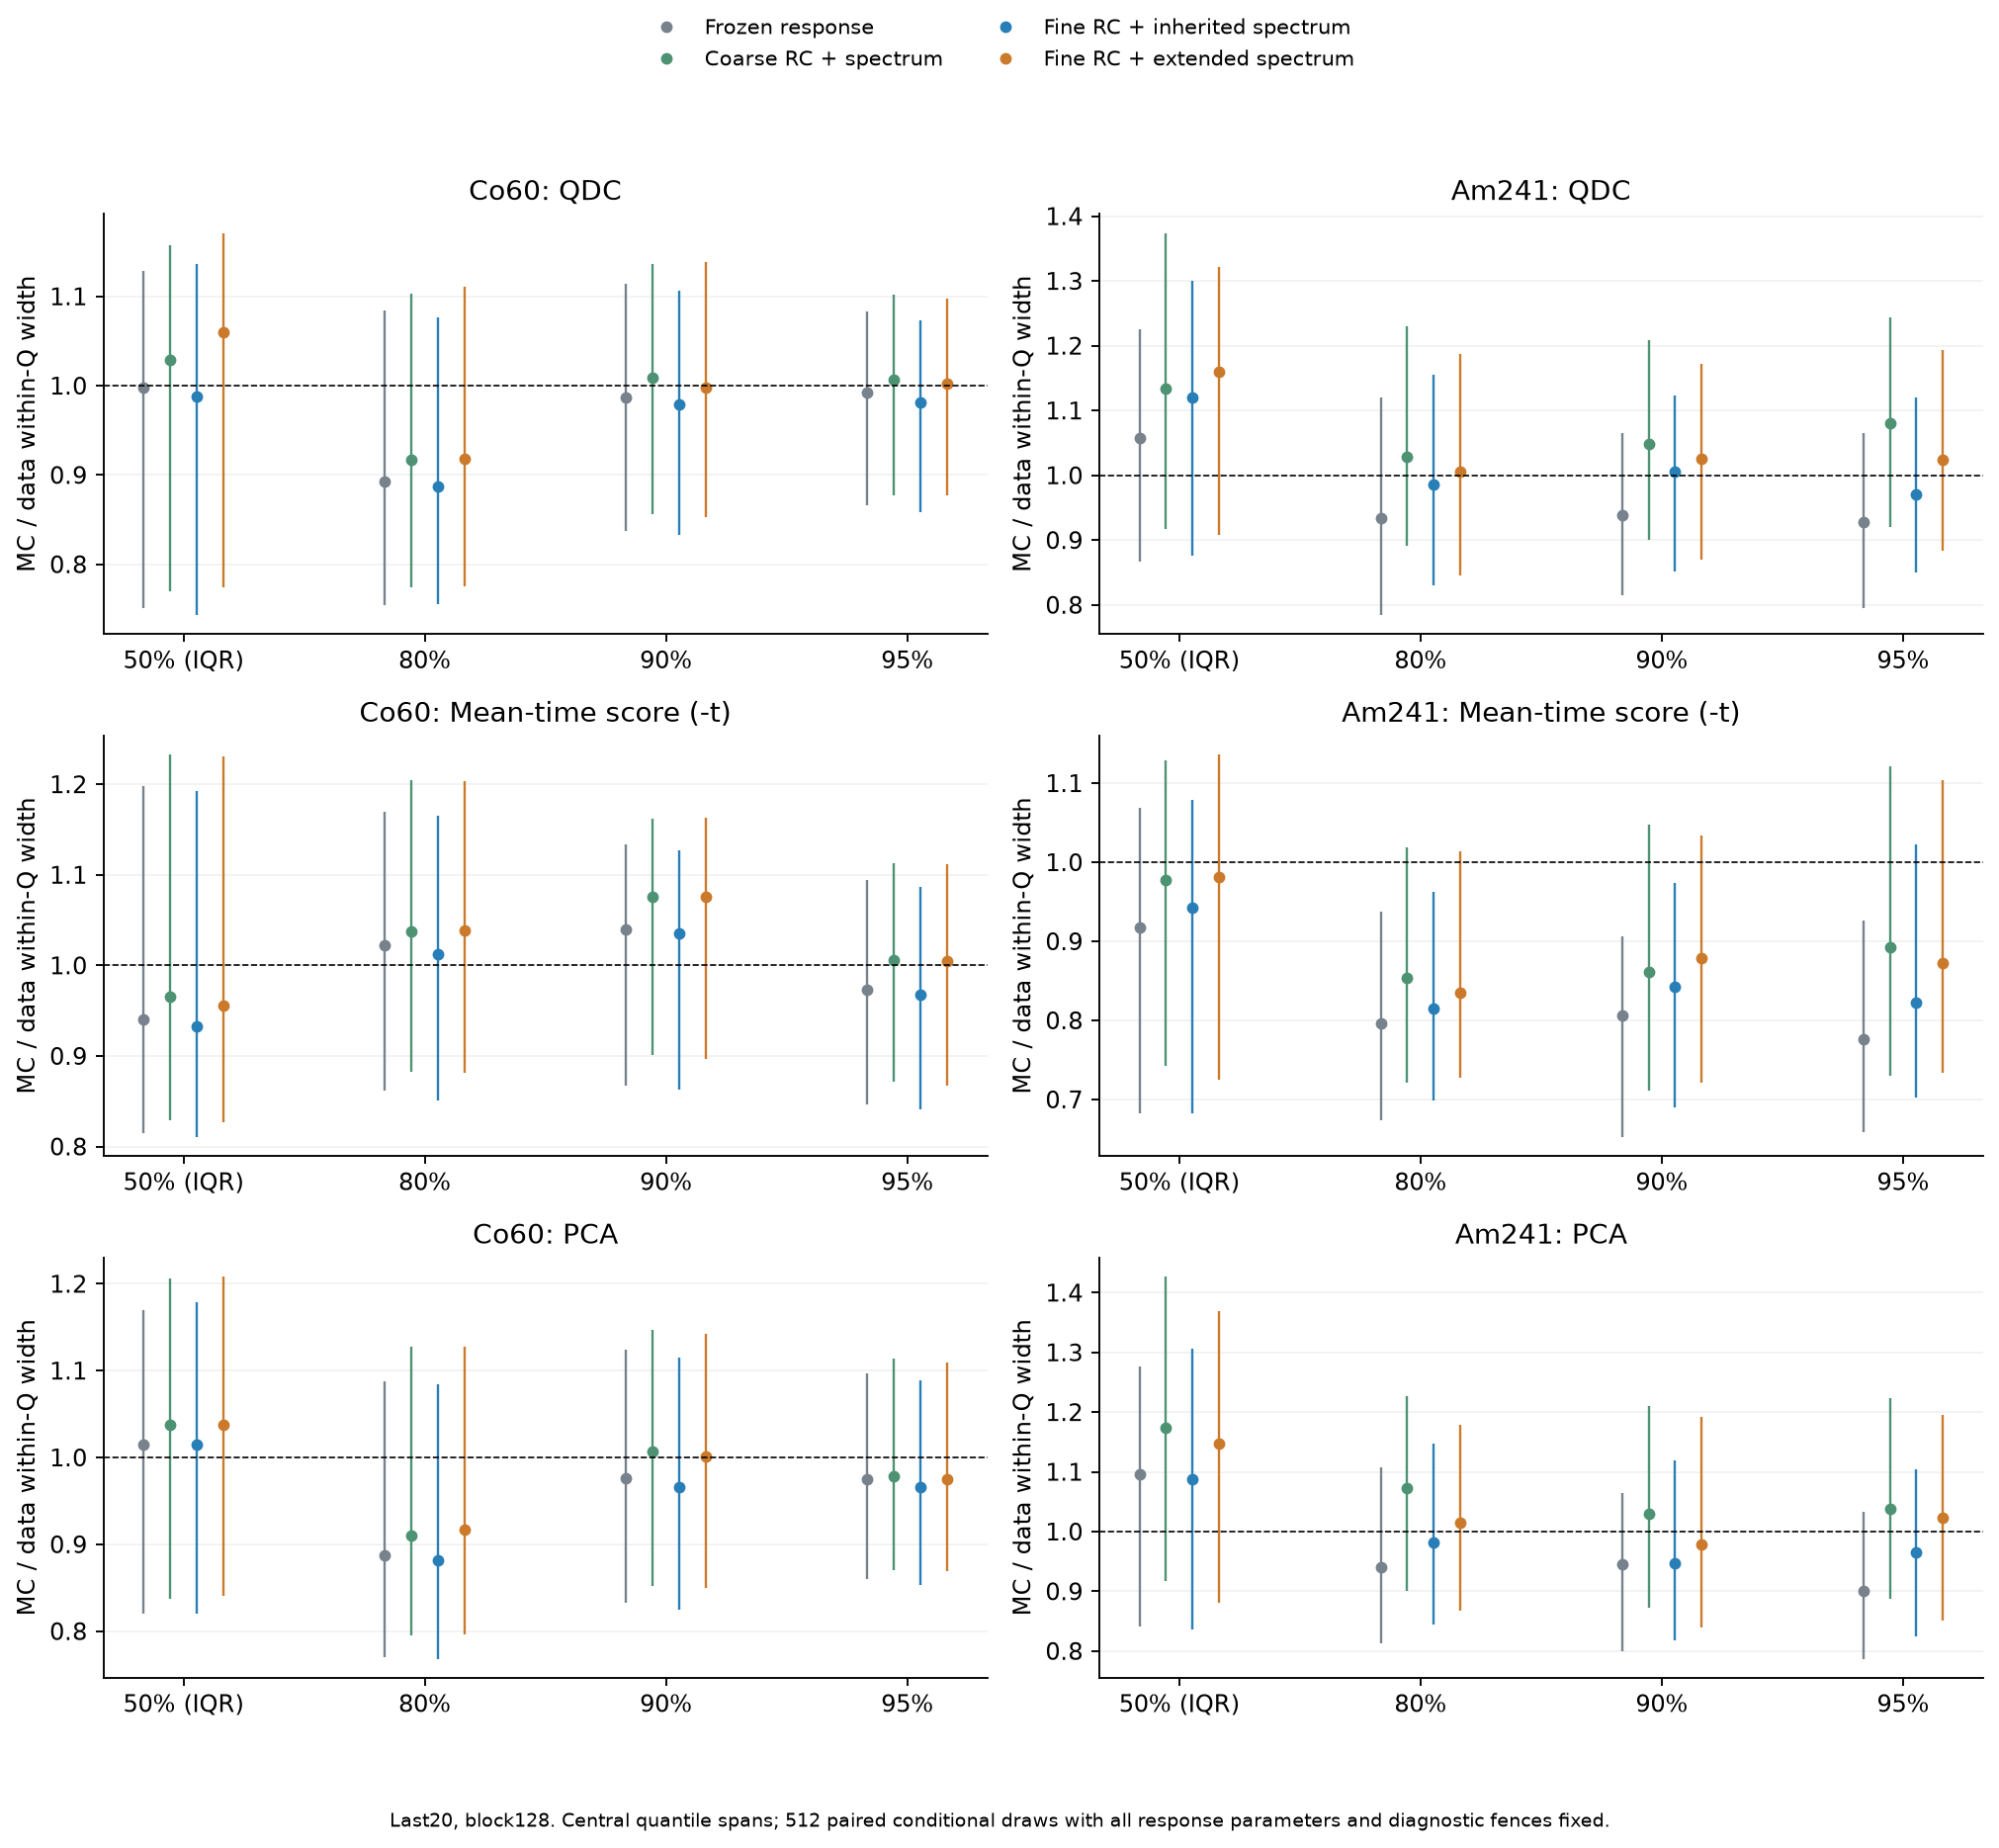

In [3]:
rows=[]
for key,blocks in e['groups'].items():
    for v in ['coarse_spectrum','inherited_CV_fit','spectrum_CV_fit']:
        r=blocks['128']['variants'][v]['point']
        rows.append([key,labels[v],nums([r[f'width50_{m}_ratio'] for m in methods]),nums([r[f'width95_{m}_ratio'] for m in methods]),nums([r[f'core_over_SD_{m}_ratio'] for m in methods])])
display(Markdown(table(['组','模型','QDC/−t/PCA IQR比','95%宽度比','核心/SD相对比'],rows)))
display(Image(filename=str(OUT/'figures/core_tail_quantile_widths.png')))

In [4]:
rows=[]
for B in ['128','64']:
    r=e['groups']['run12_last20'][B]['variants']['spectrum_CV_fit']
    for method,label in zip(methods,method_labels):
        for coverage in [50,80,90,95]:
            n=f'width{coverage}_{method}_ratio';rows.append([B,label,coverage,fmt(r['point'][n]),ci(r['CI95'][n])])
display(Markdown(table(['块长','Am晚段指标','覆盖比例/%','MC/实测宽度','条件95%区间'],rows)))

|块长|Am晚段指标|覆盖比例/%|MC/实测宽度|条件95%区间|
|---|---|---|---|---|
|128|QDC|50|1.160|[0.908, 1.321]|
|128|QDC|80|1.006|[0.845, 1.187]|
|128|QDC|90|1.025|[0.870, 1.171]|
|128|QDC|95|1.024|[0.883, 1.194]|
|128|平均时间得分−t|50|0.981|[0.725, 1.136]|
|128|平均时间得分−t|80|0.834|[0.727, 1.014]|
|128|平均时间得分−t|90|0.879|[0.721, 1.034]|
|128|平均时间得分−t|95|0.872|[0.734, 1.104]|
|128|PCA|50|1.148|[0.880, 1.370]|
|128|PCA|80|1.015|[0.868, 1.179]|
|128|PCA|90|0.978|[0.840, 1.192]|
|128|PCA|95|1.024|[0.852, 1.195]|
|64|QDC|50|1.157|[0.931, 1.389]|
|64|QDC|80|0.997|[0.862, 1.217]|
|64|QDC|90|1.031|[0.858, 1.177]|
|64|QDC|95|0.993|[0.879, 1.165]|
|64|平均时间得分−t|50|0.987|[0.756, 1.196]|
|64|平均时间得分−t|80|0.850|[0.734, 1.004]|
|64|平均时间得分−t|90|0.884|[0.726, 1.031]|
|64|平均时间得分−t|95|0.840|[0.731, 1.040]|
|64|PCA|50|1.133|[0.906, 1.408]|
|64|PCA|80|1.033|[0.871, 1.220]|
|64|PCA|90|0.970|[0.843, 1.182]|
|64|PCA|95|1.010|[0.856, 1.147]|

## 3. 尾部质量和方差贡献

每种得分分别划分尾部。方差贡献使用各评价组自己的Q箱均值作中心：
`E[(score−箱均值)² × 尾部指示] / E[(score−箱均值)²]`，最后按原定义汇总各箱二阶矩。
分母没有剔除尾部，核心贡献与尾部贡献严格相加为全方差。另存“任一指标越界”的联合尾部协方差分解。

原始尾部事件数也报告，不能把重复重采样或不同响应当新事件。零计数时经验bootstrap可能给出[0,0]，这不证明尾部率为零，更不是实验粒子泄漏率上限。


|晚段源|组|尺度边界|原支持数|QDC/−t/PCA尾部数|加权尾部占比/%|方差贡献/%|
|---|---|---|---|---|---|---|
|Co60|实测|2|821|[65, 46, 63]|7.049 / 7.124 / 8.236|27.277 / 35.767 / 33.371|
|Co60|实测|3|821|[10, 5, 7]|0.695 / 1.095 / 0.590|3.903 / 9.854 / 3.663|
|Co60|连续RC+原谱/CV选择|2|276|[20, 20, 23]|7.637 / 7.083 / 8.287|27.613 / 30.358 / 31.730|
|Co60|连续RC+原谱/CV选择|3|276|[1, 0, 3]|0.525 / 0.000 / 1.261|3.970 / 0.000 / 7.058|
|Co60|连续RC+扩展谱/CV选择|2|276|[22, 23, 24]|8.114 / 8.274 / 8.609|29.337 / 31.549 / 32.349|
|Co60|连续RC+扩展谱/CV选择|3|276|[1, 0, 4]|0.525 / 0.000 / 1.594|3.726 / 0.000 / 8.157|
|Am241|实测|2|316|[12, 16, 16]|5.053 / 4.922 / 6.489|20.365 / 21.646 / 28.356|
|Am241|实测|3|316|[0, 2, 2]|0.000 / 0.515 / 1.058|0.000 / 3.586 / 5.104|
|Am241|连续RC+原谱/CV选择|2|180|[7, 6, 9]|4.138 / 2.771 / 4.784|18.257 / 17.522 / 20.489|
|Am241|连续RC+原谱/CV选择|3|180|[0, 1, 1]|0.000 / 0.617 / 0.617|0.000 / 5.484 / 3.840|
|Am241|连续RC+扩展谱/CV选择|2|180|[9, 8, 10]|5.331 / 3.867 / 5.360|23.004 / 24.922 / 23.380|
|Am241|连续RC+扩展谱/CV选择|3|180|[1, 1, 2]|0.576 / 0.617 / 1.235|4.976 / 6.292 / 7.278|

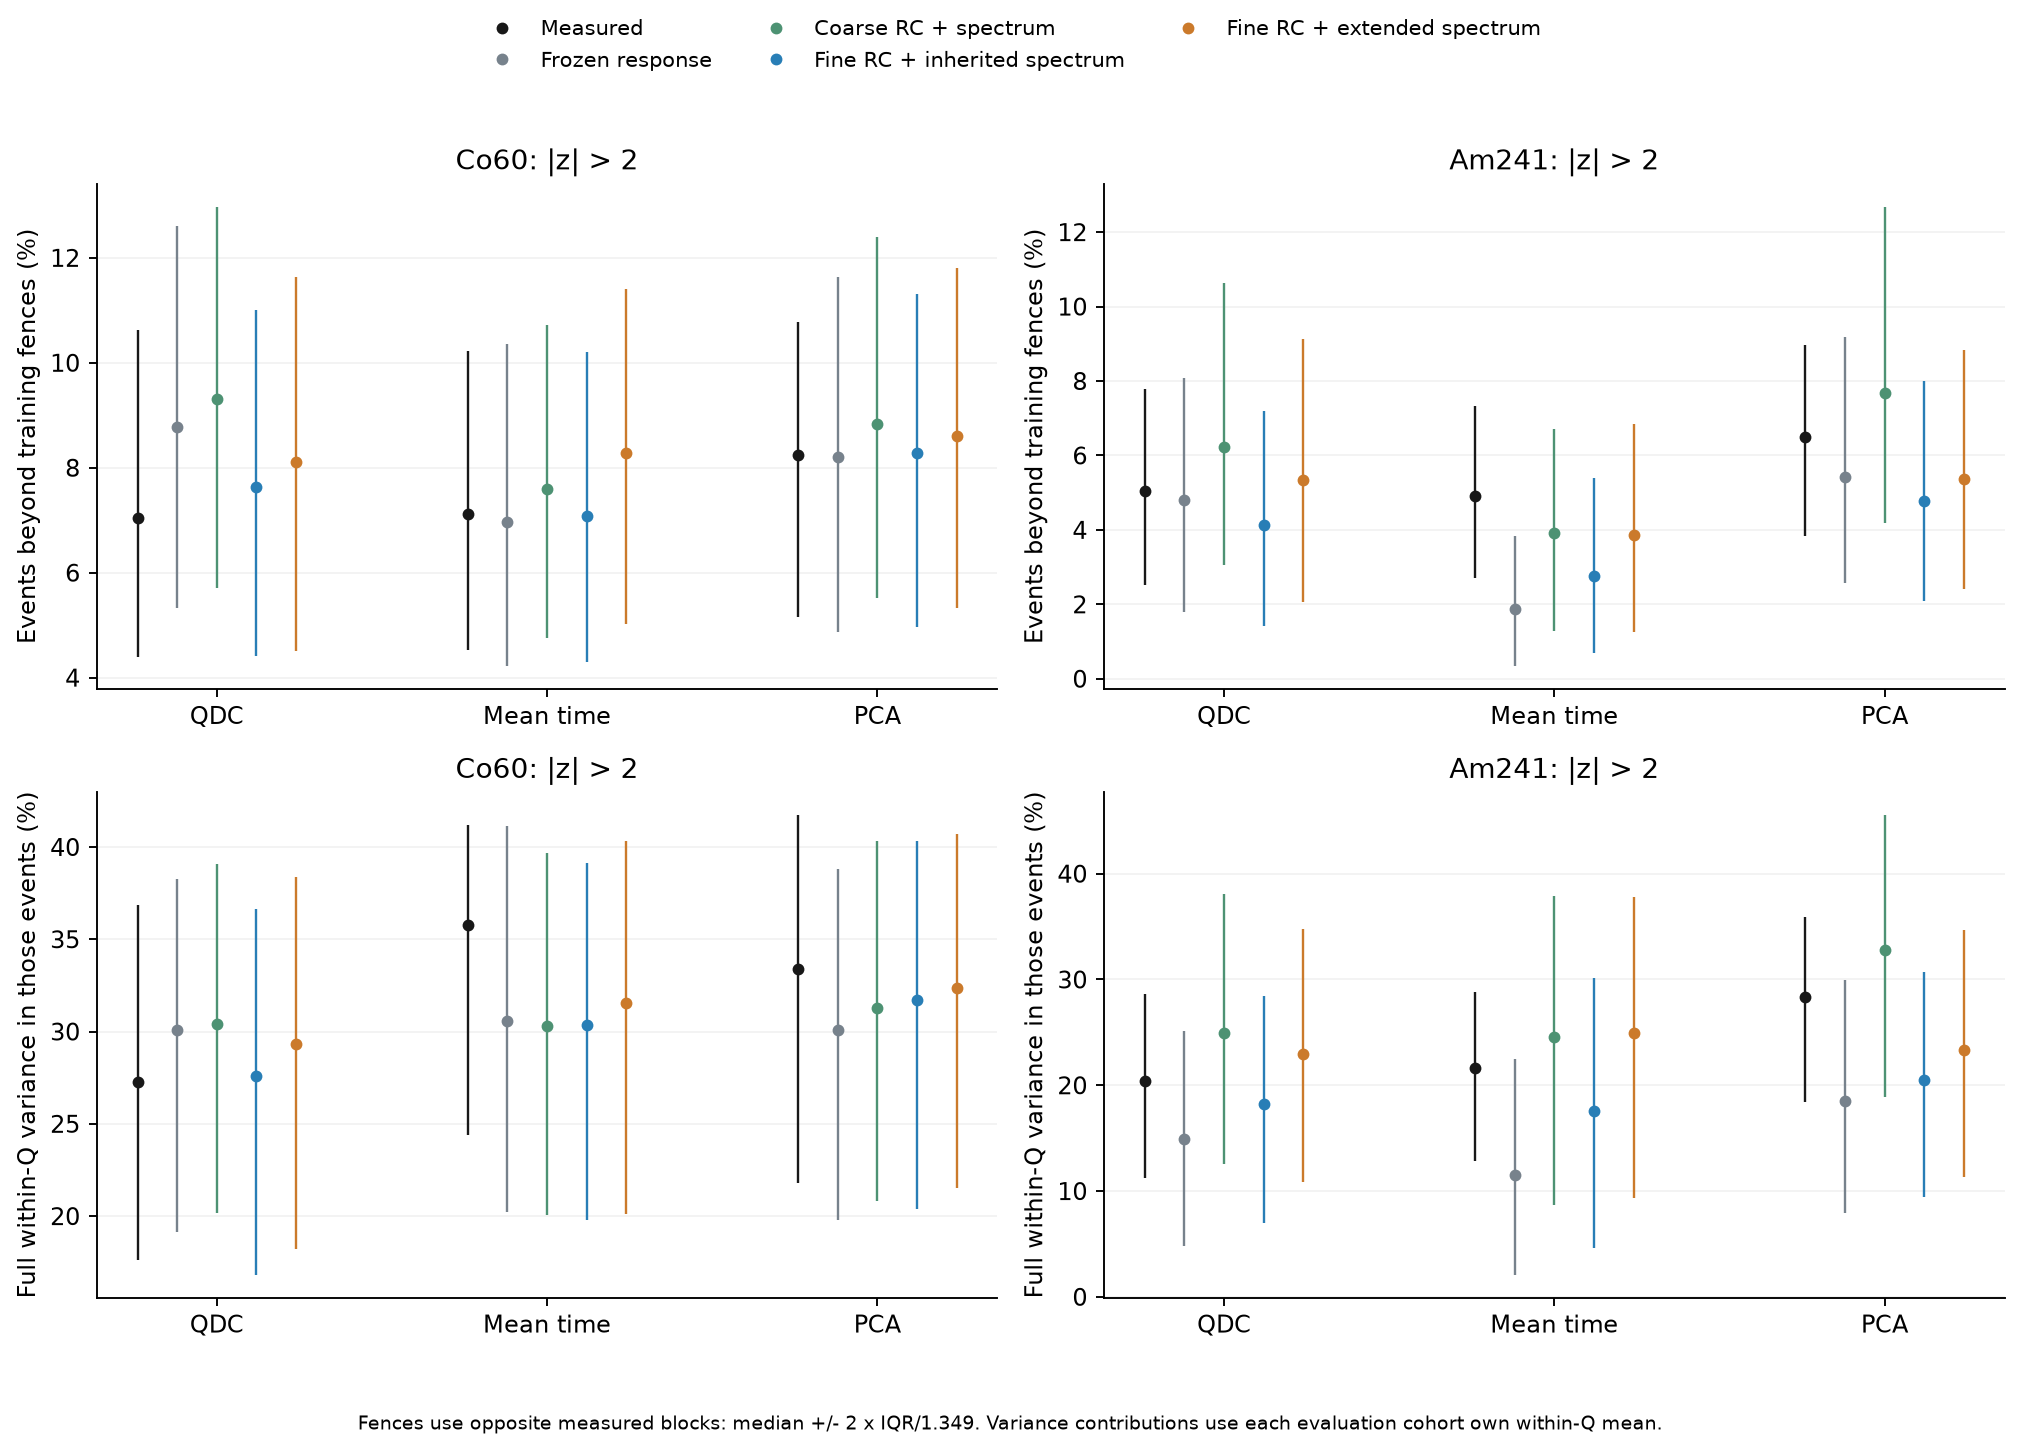

In [5]:
rows=[]
for source,run in [('Co60',3),('Am241',12)]:
    g=e['groups'][f'run{run}_last20']['128']
    for v in ['data','inherited_CV_fit','spectrum_CV_fit']:
        r=g['data'] if v=='data' else g['variants'][v]['native']
        for k,bound in enumerate([2,3]):
            rows.append([source,'实测' if v=='data' else labels[v],bound,r['supported_events'],r['tail_event_counts'][k],nums(100*np.array(r['tail_probability'][k])),nums(100*np.array(r['tail_variance_share'][k]))])
display(Markdown(table(['晚段源','组','尺度边界','原支持数','QDC/−t/PCA尾部数','加权尾部占比/%','方差贡献/%'],rows)))
display(Image(filename=str(OUT/'figures/core_tail_mass_and_variance.png')))

|Am晚段|MC−实测|点估计|条件95%区间|
|---|---|---|---|
|QDC|尾部质量差/百分点|0.278|[-3.617, 4.281]|
|QDC|尾部方差贡献差/百分点|2.639|[-11.507, 16.866]|
|平均时间得分−t|尾部质量差/百分点|-1.056|[-4.904, 2.566]|
|平均时间得分−t|尾部方差贡献差/百分点|3.276|[-13.552, 19.670]|
|PCA|尾部质量差/百分点|-1.129|[-5.115, 3.170]|
|PCA|尾部方差贡献差/百分点|-4.976|[-19.000, 9.448]|

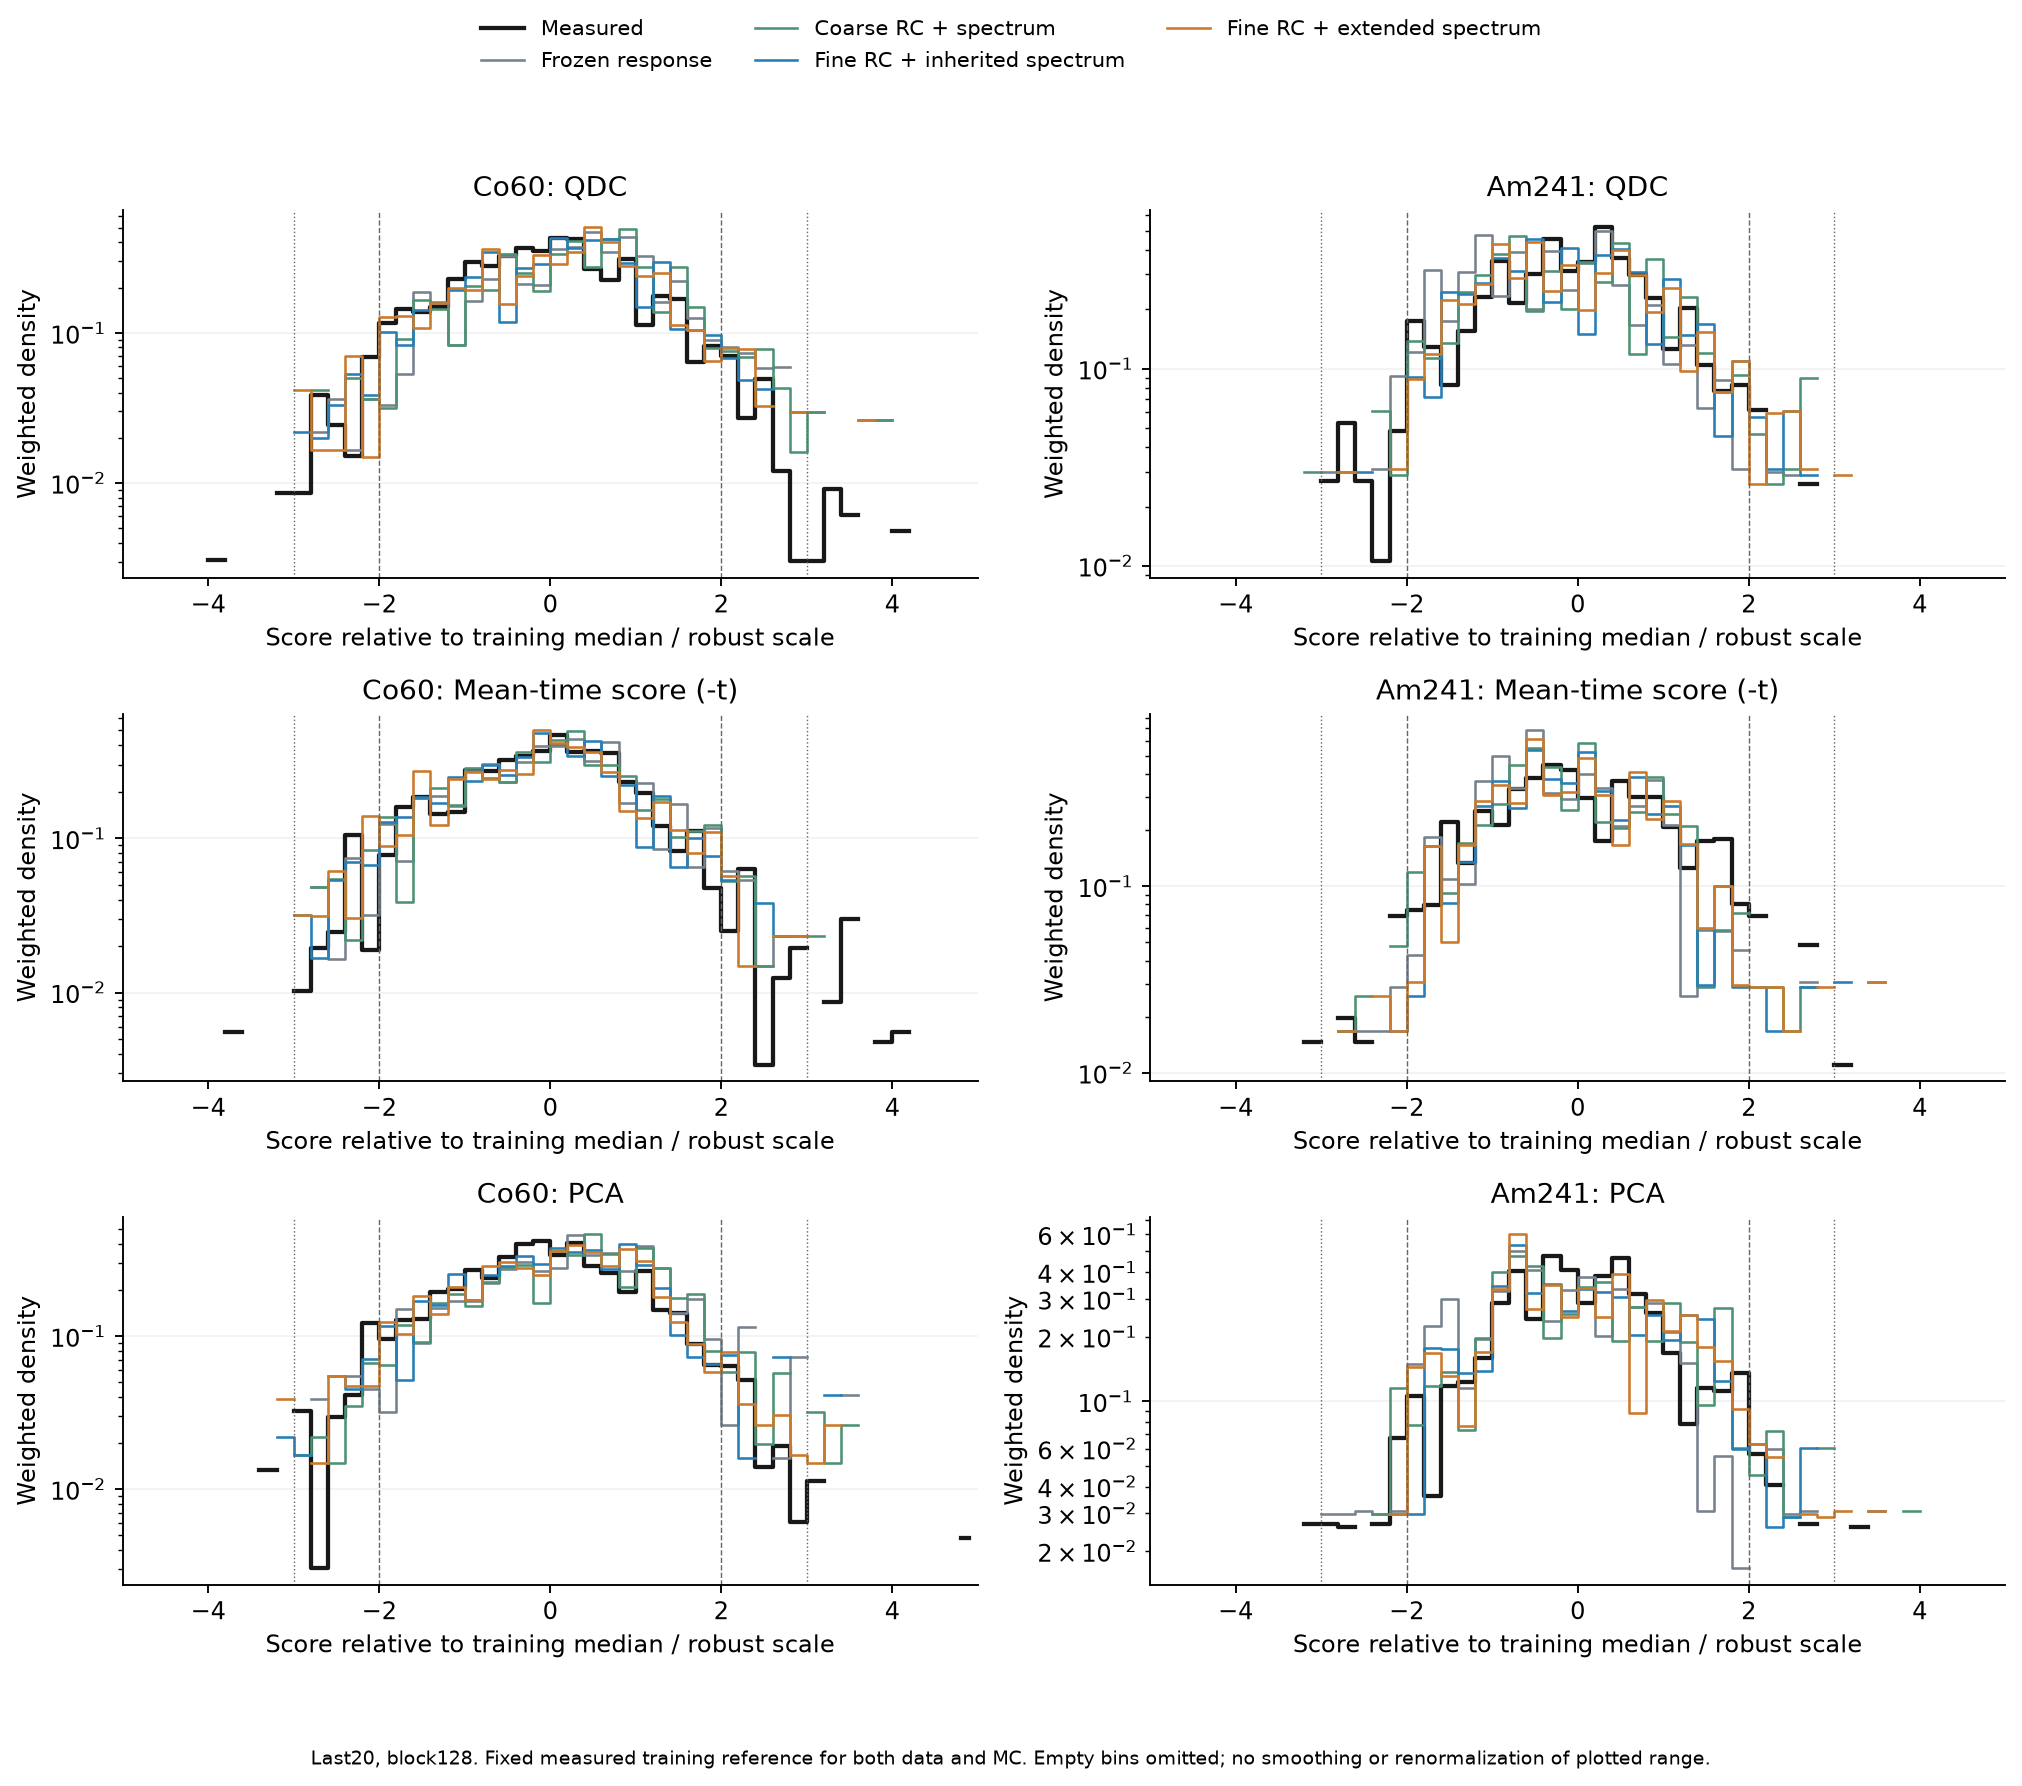

|源|组|图示±5范围外QDC/−t/PCA质量/%|
|---|---|---|
|Co60|实测|0.000 / 0.000 / 0.000|
|Co60|粗RC+扩展谱|0.000 / 0.000 / 0.000|
|Co60|连续RC+原谱/CV选择|0.000 / 0.000 / 0.000|
|Co60|连续RC+扩展谱/CV选择|0.000 / 0.000 / 0.000|
|Am241|实测|0.000 / 0.000 / 0.000|
|Am241|粗RC+扩展谱|0.000 / 0.000 / 0.000|
|Am241|连续RC+原谱/CV选择|0.000 / 0.000 / 0.000|
|Am241|连续RC+扩展谱/CV选择|0.000 / 0.000 / 0.000|

In [6]:
r=e['groups']['run12_last20']['128']['variants']['spectrum_CV_fit'];rows=[]
for m,label in zip(methods,method_labels):
    for stem,title in [('tail2','尾部质量差/百分点')]:
        n=f'{stem}_{m}_mass_delta_pp';rows.append([label,title,fmt(r['point'][n]),ci(r['CI95'][n])])
    n=f'tail2_{m}_variance_share_delta_pp';rows.append([label,'尾部方差贡献差/百分点',fmt(r['point'][n]),ci(r['CI95'][n])])
display(Markdown(table(['Am晚段','MC−实测','点估计','条件95%区间'],rows)))
display(Image(filename=str(OUT/'figures/core_tail_distributions.png')))
rows=[]
for source,run in [('Co60',3),('Am241',12)]:
    g=e['groups'][f'run{run}_last20']['128']
    for v in ['data','coarse_spectrum','inherited_CV_fit','spectrum_CV_fit']:
        r=g['data'] if v=='data' else g['variants'][v]['native']
        rows.append([source,'实测' if v=='data' else labels[v],nums(100*np.array(r['histogram']['outside_range_mass']))])
display(Markdown(table(['源','组','图示±5范围外QDC/−t/PCA质量/%'],rows)))

## 4. 尾部对应的波形与起伏

每条波形的76个40 ns门电荷份额之和为1。对每个原Q箱，以该评价组的得分均值及波形份额均值居中，计算交叉协方差，再汇总并除以完整得分SD。
虚线为`|z|>2`事件对该协方差的贡献，实线为全体事件；虚线不是“尾部事件的平均波形”。核心与尾部贡献严格相加。

另列PID与前128点基线RMS对数、F50/102/202的箱内相关。PID与F共享样点，门电荷份额还共享归一化，因此这些关联不能单独识别物理机制。


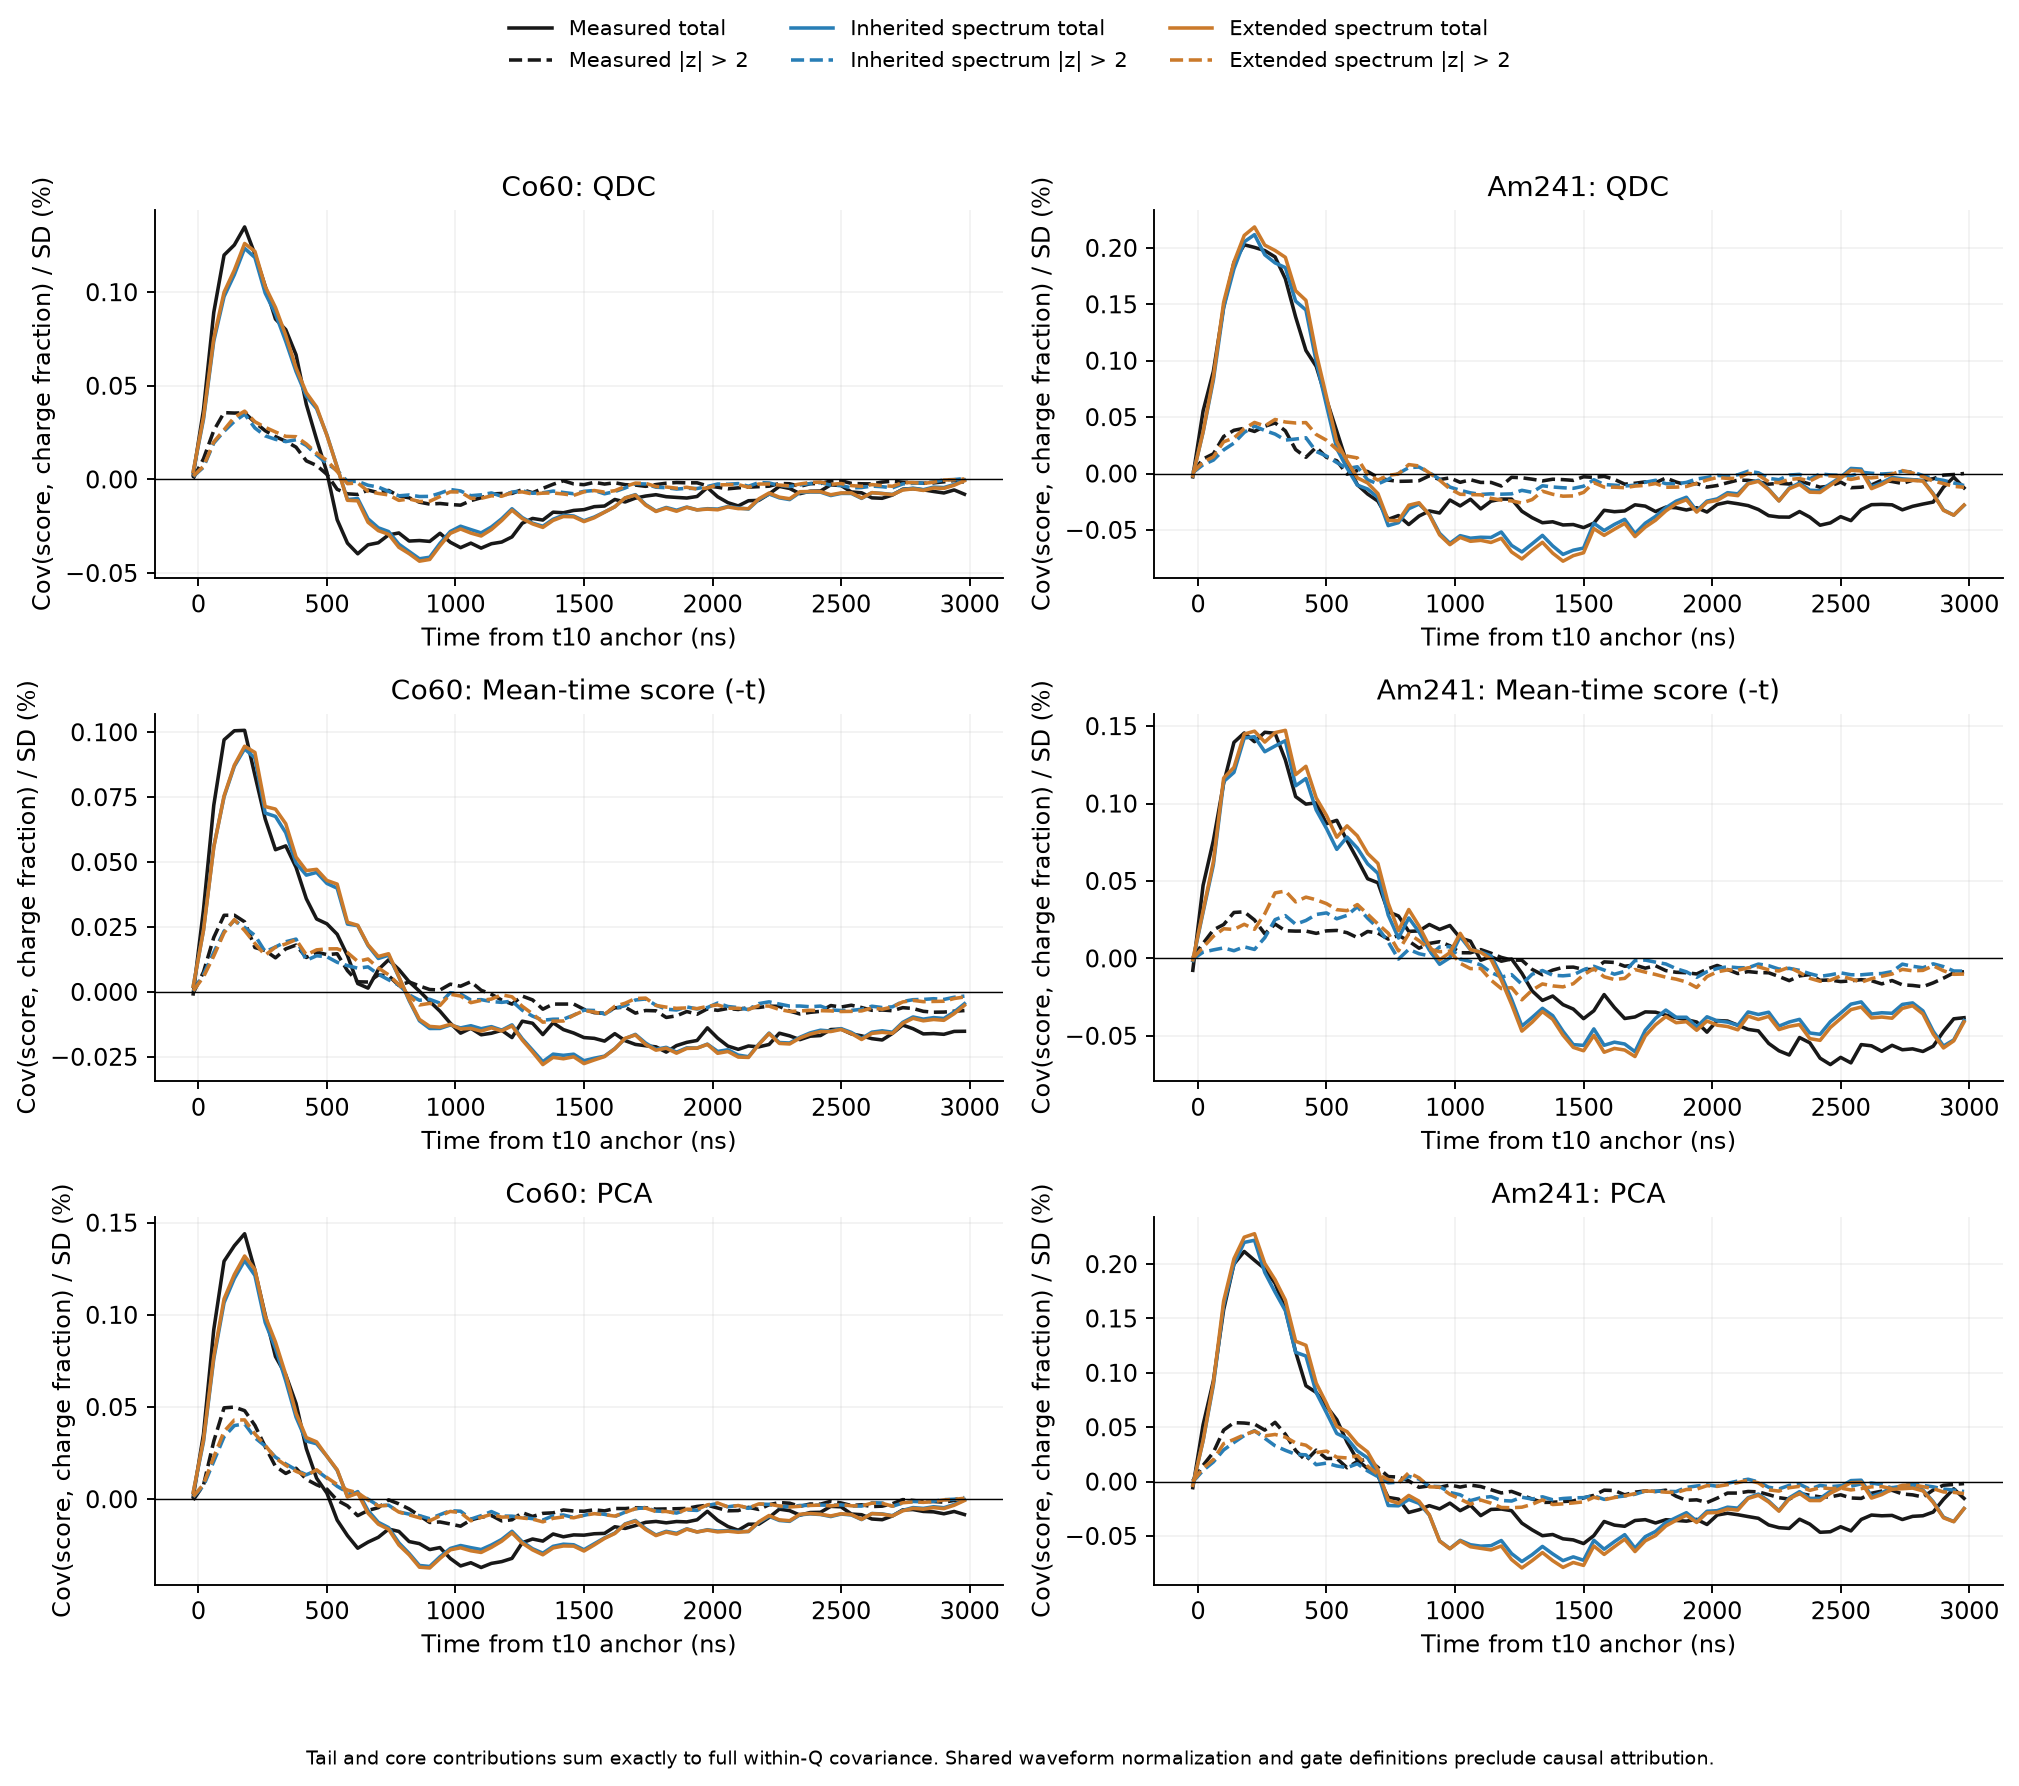

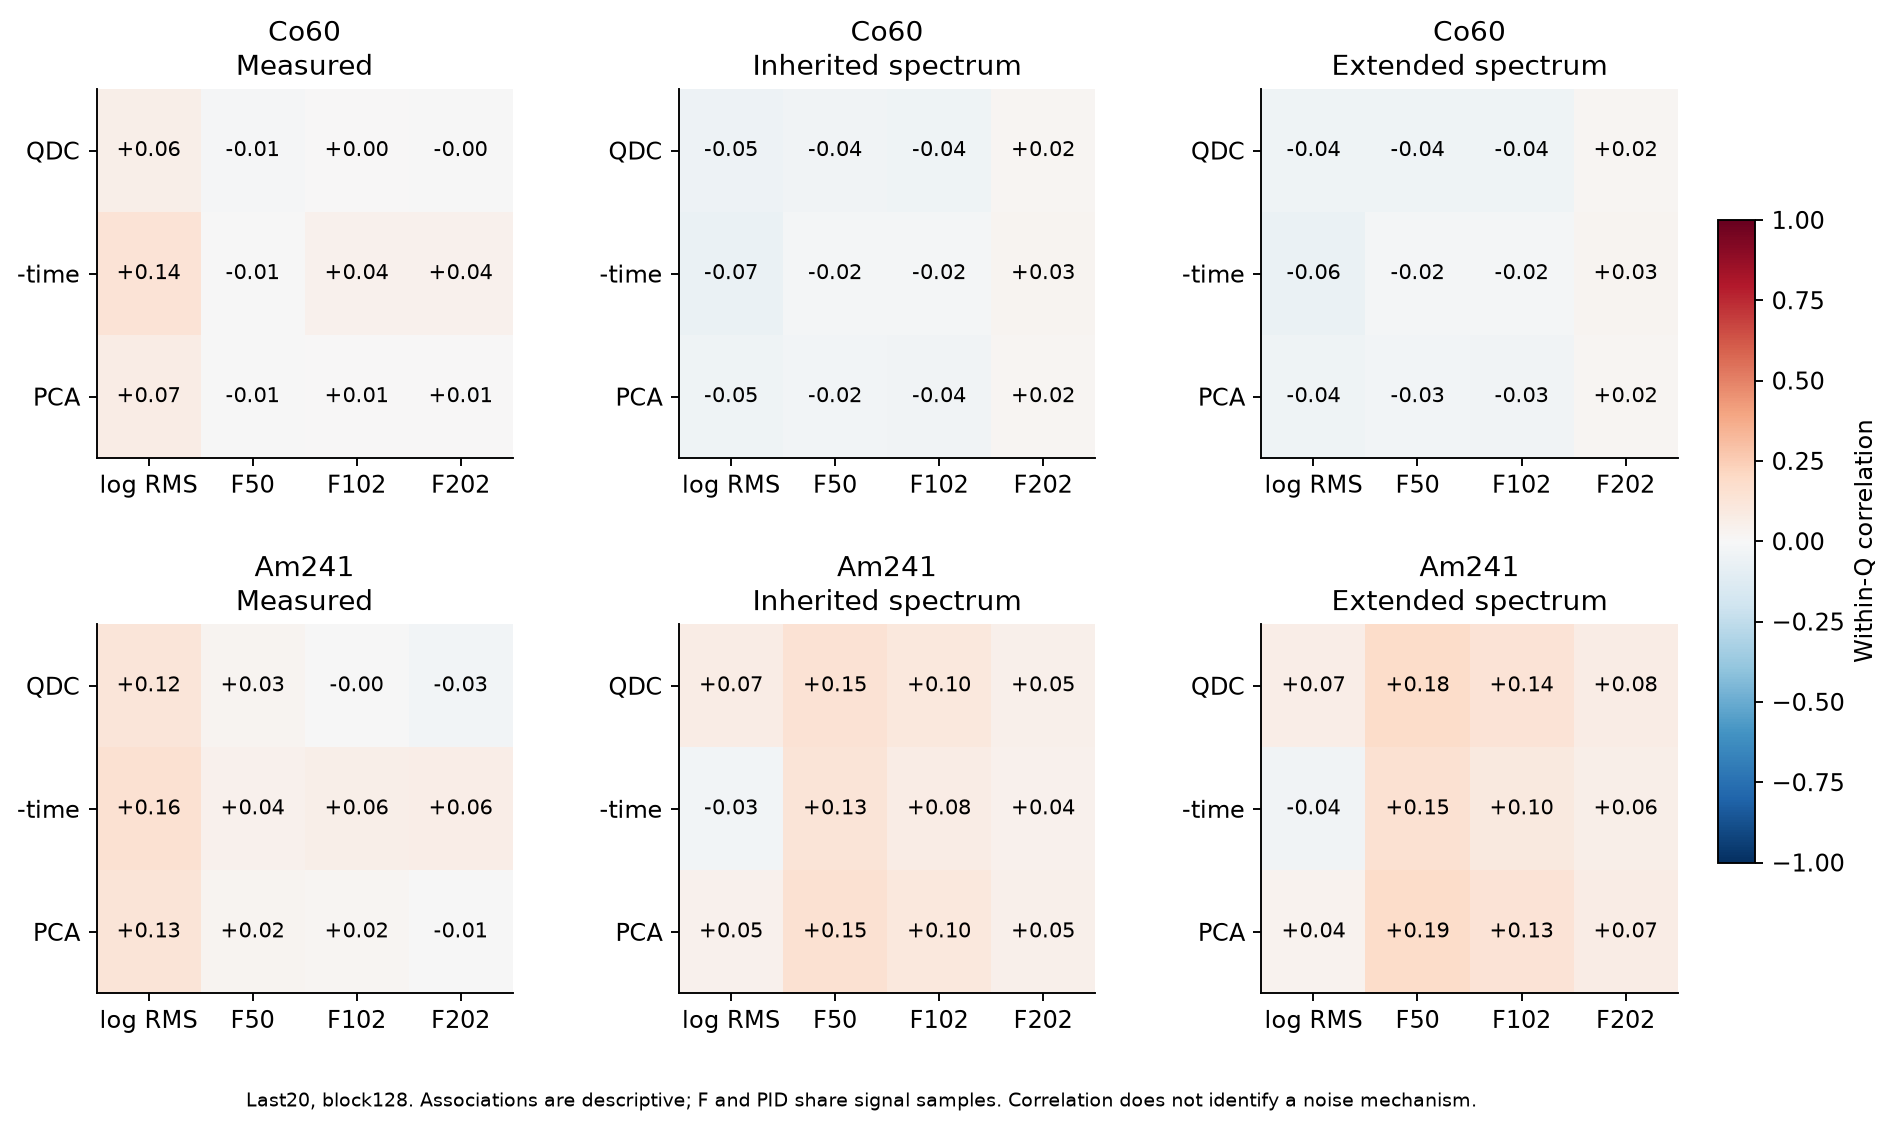

In [7]:
display(Image(filename=str(OUT/'figures/core_tail_waveform_covariance.png')))
display(Image(filename=str(OUT/'figures/core_tail_noise_associations.png')))

## 5. 现有Geant4祖先标签检查

从原生输运ROOT重新读取CsI能量沉积及雪崩电荷的祖先贡献。祖先类别为unknown、α、γ、衰变电子、其他等；类别不是当前沉积粒子的种类。
某类占总贡献≥90%才称该家族主导，另以能量95%及雪崩电荷90%检查定义敏感性。
雪崩电荷是原窗口中实际雪崩电荷，不等于有限门ADC积分。α主导事件仍可能含次要γ/电子贡献。

在每个Q箱按能量90%主导类分解完整协方差为“类别均值之间”与“类别内”两项。
若一个支持区只有一类，类别间项为0；这只排除这组粗类别混合对已选择MC的贡献，不排除类内能损、光收集和响应变化，也不说明实验纯度。


In [8]:
rows=[]
for source,run in [('Co60',3),('Am241',12)]:
    r=e['groups'][f'run{run}_last20']['128']['variants']['spectrum_CV_fit']['ancestry']
    for key,s in r['label_sensitivity'].items():rows.append([source,key,s['counts'],nums(s['weighted_fractions'])])
    print(source,'类间均值方差/总方差:',r['between_truth_mean_variance_fraction'])
display(Markdown(table(['源','定义','α/γ/衰变电子/混合其他/无沉积原数','对应加权份额'],rows)))
rows=[]
for source,run in [('Co60',3),('Am241',12)]:
    r=e['groups'][f'run{run}_last20']['128']['variants']['spectrum_CV_fit']['ancestry']
    for key,s in r['counts'].items():
        if s['events']:rows.append([source,key,s['events'],s['joint_tail_events'],fmt(s['tail_probability_given_class']),s['Q_bins_present']])
display(Markdown(table(['源','能量90%类','支持数','任一PID越界原数','类内加权联合尾部率','存在Q箱'],rows)))

Co60 类间均值方差/总方差: [4.083473906785329e-29, 1.7888790416265947e-29, 9.54430900408831e-31]
Am241 类间均值方差/总方差: [8.16959029138339e-30, 2.1401970221748915e-29, 1.8551147832416047e-31]


|源|定义|α/γ/衰变电子/混合其他/无沉积原数|对应加权份额|
|---|---|---|---|
|Co60|label_energy90|[0, 276, 0, 0, 0]|0.000 / 1.000 / 0.000 / 0.000 / 0.000|
|Co60|label_energy95|[0, 276, 0, 0, 0]|0.000 / 1.000 / 0.000 / 0.000 / 0.000|
|Co60|label_charge90|[0, 276, 0, 0, 0]|0.000 / 1.000 / 0.000 / 0.000 / 0.000|
|Am241|label_energy90|[180, 0, 0, 0, 0]|1.000 / 0.000 / 0.000 / 0.000 / 0.000|
|Am241|label_energy95|[180, 0, 0, 0, 0]|1.000 / 0.000 / 0.000 / 0.000 / 0.000|
|Am241|label_charge90|[180, 0, 0, 0, 0]|1.000 / 0.000 / 0.000 / 0.000 / 0.000|

|源|能量90%类|支持数|任一PID越界原数|类内加权联合尾部率|存在Q箱|
|---|---|---|---|---|---|
|Co60|gamma_family|276|44|0.158|[0, 1, 2, 3, 4, 5]|
|Am241|alpha_family|180|18|0.093|[0, 1, 2]|

## 6. 判断与后续工作


In [9]:
display(Markdown(decision['conclusion_zh']))
for finding in decision['findings_zh']:display(Markdown(finding))
display(Markdown(decision['next_work_zh']))
for limit in decision['limitations_zh']:display(Markdown('边界：'+limit))
print('默认配置已替换:',decision['default_changed'])
print('复现: prepare_pid_core_tail.py → analyze_pid_core_tail.py → plot_pid_core_tail.py → summarize_pid_core_tail.py')
print('笔记: jupyter/codex_0001_build_pid_core_tail_notebook.py；核验: verify_pid_core_tail.py，随后 --archive')
print('完整结果目录:',OUT)

默认配置已替换: False
复现: prepare_pid_core_tail.py → analyze_pid_core_tail.py → plot_pid_core_tail.py → summarize_pid_core_tail.py
笔记: jupyter/codex_0001_build_pid_core_tail_notebook.py；核验: verify_pid_core_tail.py，随后 --archive
完整结果目录: /media/sf_works/SiPM/simulation/results/pid_core_tail_20261030


本轮固定模拟参数和原事件全集，完成PID核心、外侧分位宽度、尾部方差及波形关联检查。Am晚段扩展谱（块128）的QDC/PCA核心IQR比为1.160/1.148，而95%分位宽度比为1.024/1.024；平均时间IQR比为0.981，80%/95%分位宽度比为0.834/0.872。点估计提示核心与外侧分布的形状差异，不能用一个整体加宽系数解决；这些宽度比的条件95%区间均包含1，不能称为已确认的分布失配机制。

Am晚段QDC/平均时间/PCA超出训练块±2稳健尺度边界的加权比例，实测为5.05%/4.92%/6.49%，MC为5.33%/3.87%/5.36%。三项差值区间均包含0；MC对应原事件仅为[9, 8, 10]条，不能由有限尾部样本确定稀有事件模型。

上述尾部对完整箱内方差的贡献，实测为20.4%/21.6%/28.4%，MC为23.0%/24.9%/23.4%。占比差的条件区间均包含0，不能简单断言实验异常尾部支配了差异。

当前支持Q箱内的276个Co原母事件全为γ家族主导，180个Am原母事件全为α家族主导；能量90%/95%和雪崩电荷90%三个定义一致。按这些标签分解的类间均值方差为0，因此这批已选择MC中的粒子家族混合不能解释其核心/尾部差异；亚主导贡献和类内能损涨落并未被排除，更不能据此给实验赋真值。

新增波形图显示每种PID与40 ns门电荷份额的协方差，并将尾部贡献单独列出；全体事件保持不变。PID、F与归一化波形共享样点，相关性仅用作定位线索，不可单独确认噪声、闪烁或电路原因。

... (3 outputs left out)

边界：配对区间固定响应参数、谱族选择和诊断边界，不包含其拟合误差；未进行等效性检验或多重比较校正。

边界：尾部事件很少，零计数可使经验bootstrap区间退化，不能当作尾部率为零或粒子泄漏上限。

边界：±2/3尺度采用训练中位数及IQR/1.349，不假定尾部服从高斯分布；它们仅为诊断边界。

边界：能量及雪崩祖先标签只用于已有MC，主导类相同不等于每条事件没有次要成分；实验Am主带不能当作纯α。

`protocol.json`在新数值检查之前固定方案、输入哈希和提交号；`references/`保存每折训练/评价ID及边界。
`diagnostics.json`含逐Q箱结果、宽度区间、精确方差和波形协方差分解；`bootstrap.npz`保留配对抽样；`validation_table.csv`为60行全候选数值表。
最后核验IQR/SD点估计及区间与上一轮逐项一致，并直接从事件重算尾部质量和方差、检查祖先能量/电荷守恒、执行笔记和嵌入图。
`verification.json`与`record.json`封存结果及源码哈希。复跑使用新目录，不覆盖当前记录。共享文献库未修改，本轮未联网或新增实验。
